# Evaluation of Operating System Random Number Generation Mechanisms

## Objective
To evaluate operating-system random-number generation mechanisms and investigate their suitability for cryptographic applications.

## Random Number Generators Compared
1. Linux `/dev/urandom`
2. OpenSSL `rand`
3. Windows CNG using .NET `RandomNumberGenerator`

## Dataset Size
1 MiB (1,048,576 bytes) per generator.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from collections import Counter

# Dataset directory
DATA_DIR = Path("data")

# Load all three random datasets
datasets = {
    "Linux /dev/urandom": np.fromfile(DATA_DIR / "linux_urandom.bin", dtype=np.uint8),
    "OpenSSL rand": np.fromfile(DATA_DIR / "openssl_rand.bin", dtype=np.uint8),
    "Windows CNG": np.fromfile(DATA_DIR / "windows_cng.bin", dtype=np.uint8)
}

# Display dataset information
for name, data in datasets.items():
    print(f"{name}:")
    print(f"  Size: {len(data):,} bytes")
    print(f"  Data type: {data.dtype}")
    print()

Linux /dev/urandom:
  Size: 1,048,576 bytes
  Data type: uint8

OpenSSL rand:
  Size: 1,048,576 bytes
  Data type: uint8

Windows CNG:
  Size: 1,048,576 bytes
  Data type: uint8




Linux /dev/urandom
Minimum frequency: 3922
Maximum frequency: 4287
Mean frequency: 4096.00
Expected frequency: 4096.00

OpenSSL rand
Minimum frequency: 3914
Maximum frequency: 4255
Mean frequency: 4096.00
Expected frequency: 4096.00

Windows CNG
Minimum frequency: 3930
Maximum frequency: 4272
Mean frequency: 4096.00
Expected frequency: 4096.00


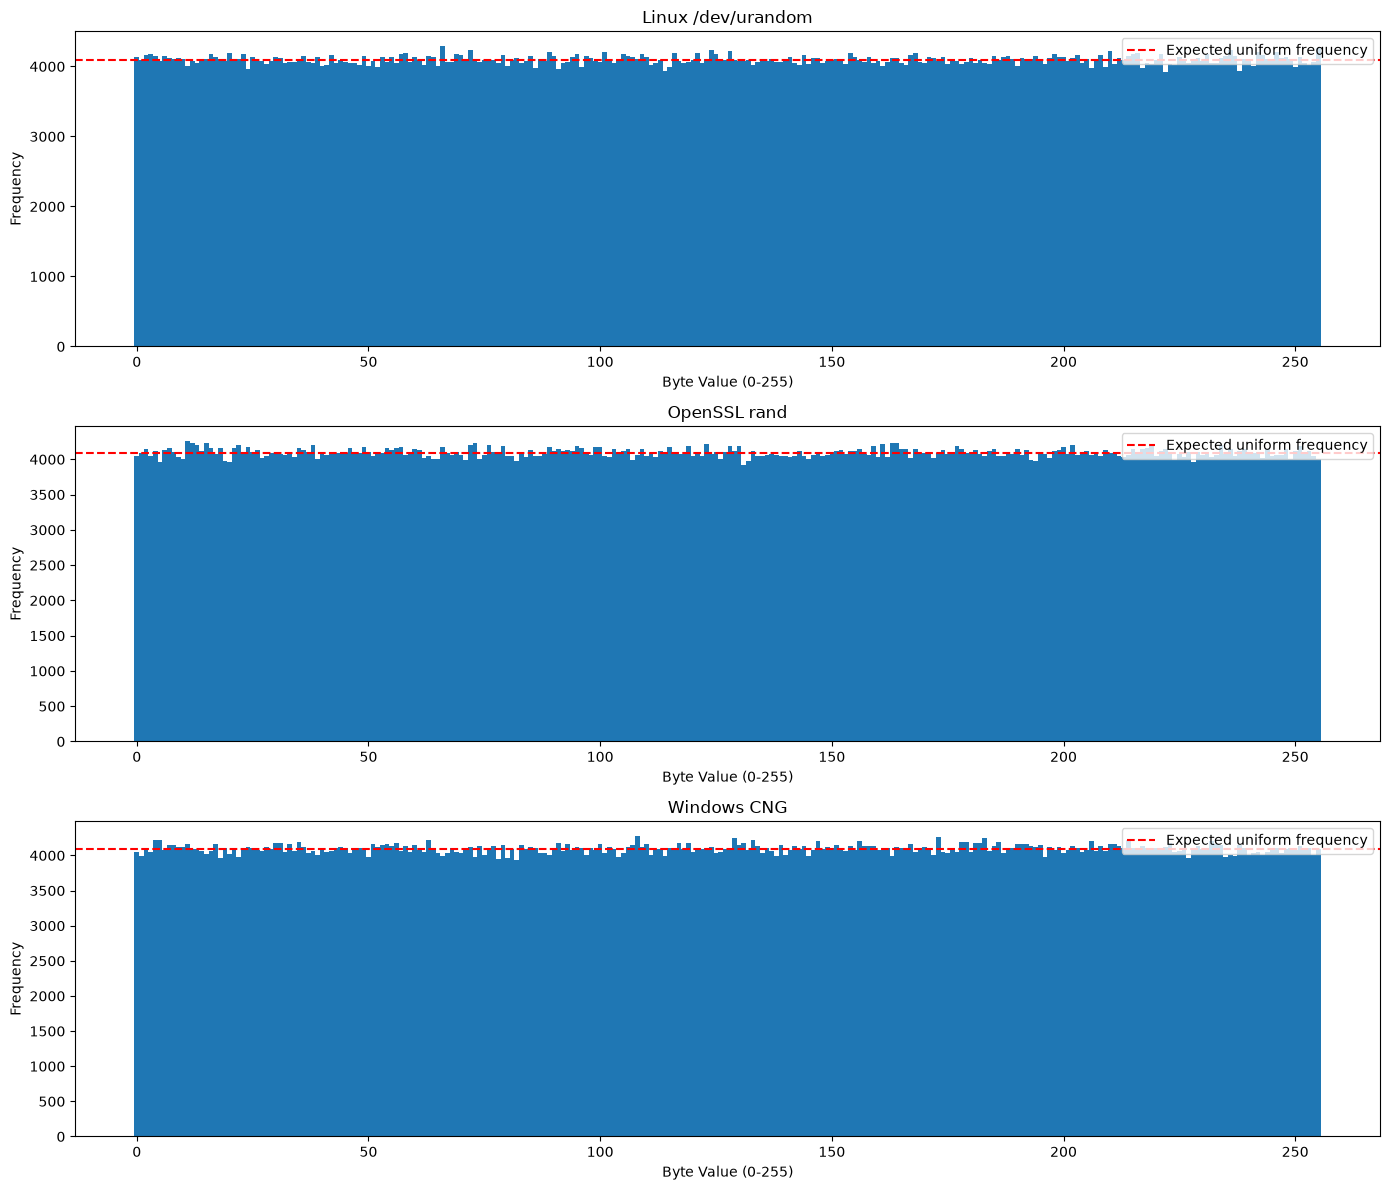

In [2]:
# BYTE FREQUENCY DISTRIBUTION

byte_frequencies = {}

for name, data in datasets.items():
    frequencies = np.bincount(data, minlength=256)
    byte_frequencies[name] = frequencies

    print(f"\n{name}")
    print(f"Minimum frequency: {frequencies.min()}")
    print(f"Maximum frequency: {frequencies.max()}")
    print(f"Mean frequency: {frequencies.mean():.2f}")
    print(f"Expected frequency: {len(data) / 256:.2f}")

# Plot byte-frequency distributions
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for ax, (name, frequencies) in zip(axes, byte_frequencies.items()):
    ax.bar(range(256), frequencies, width=1)
    ax.axhline(len(datasets[name]) / 256,
               linestyle="--", color="red",
               label="Expected uniform frequency")
    ax.set_title(name)
    ax.set_xlabel("Byte Value (0-255)")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

In [3]:
# CHI-SQUARE GOODNESS-OF-FIT TEST

print("CHI-SQUARE TEST RESULTS")
print("=" * 65)

chi_square_results = []

for name, frequencies in byte_frequencies.items():

    expected = np.full(256, len(datasets[name]) / 256)

    chi_stat, p_value = stats.chisquare(
        f_obs=frequencies,
        f_exp=expected
    )

    result = "Fail to reject H0" if p_value >= 0.05 else "Reject H0"

    chi_square_results.append({
        "Generator": name,
        "Chi-square Statistic": chi_stat,
        "P-value": p_value,
        "Conclusion": result
    })

    print(f"\n{name}")
    print(f"Chi-square statistic: {chi_stat:.4f}")
    print(f"P-value: {p_value:.6f}")
    print(f"Conclusion: {result}")

chi_square_df = pd.DataFrame(chi_square_results)

CHI-SQUARE TEST RESULTS

Linux /dev/urandom
Chi-square statistic: 227.9971
P-value: 0.887040
Conclusion: Fail to reject H0

OpenSSL rand
Chi-square statistic: 221.8638
P-value: 0.934004
Conclusion: Fail to reject H0

Windows CNG
Chi-square statistic: 234.1646
P-value: 0.821024
Conclusion: Fail to reject H0


,Generator,Zeros,Ones,Zero %,One %
0,Linux /dev/urandom,4194501,4194107,50.002348,49.997652
1,OpenSSL rand,4193698,4194910,49.992776,50.007224
2,Windows CNG,4192092,4196516,49.973631,50.026369


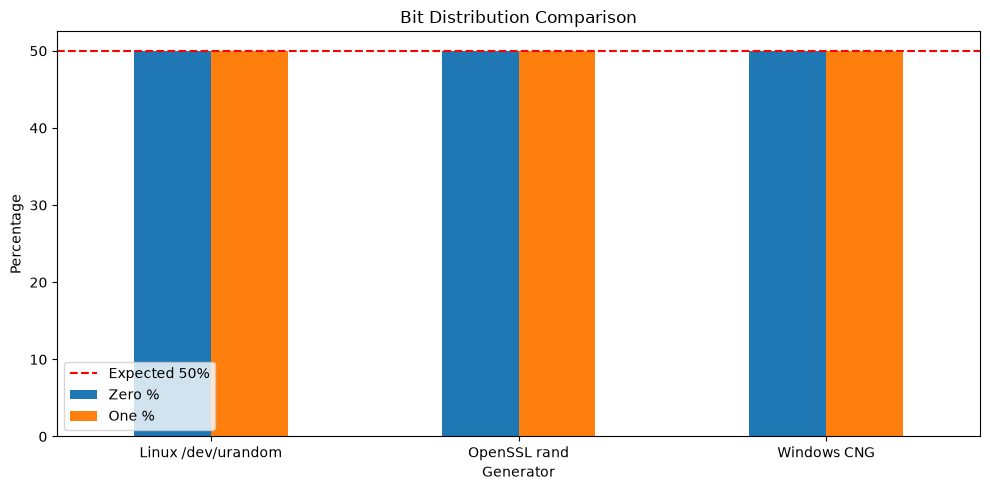

In [4]:
# BIT FREQUENCY ANALYSIS

bit_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)

    zeros = np.count_nonzero(bits == 0)
    ones = np.count_nonzero(bits == 1)
    total = len(bits)

    bit_results.append({
        "Generator": name,
        "Zeros": zeros,
        "Ones": ones,
        "Zero %": zeros / total * 100,
        "One %": ones / total * 100
    })

bit_df = pd.DataFrame(bit_results)
display(bit_df)

# Plot bit distributions
bit_df.set_index("Generator")[["Zero %", "One %"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.axhline(50, color="red", linestyle="--", label="Expected 50%")
plt.ylabel("Percentage")
plt.title("Bit Distribution Comparison")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# BINOMIAL TEST FOR BIT BALANCE

print("BIT BALANCE TEST RESULTS")
print("=" * 65)

bit_test_results = []

for name, data in datasets.items():

    bits = np.unpackbits(data)
    ones = int(np.count_nonzero(bits == 1))
    total = len(bits)

    test = stats.binomtest(
        ones,
        n=total,
        p=0.5,
        alternative="two-sided"
    )

    conclusion = (
        "Fail to reject H0"
        if test.pvalue >= 0.05
        else "Reject H0"
    )

    bit_test_results.append({
        "Generator": name,
        "Ones": ones,
        "Total Bits": total,
        "P-value": test.pvalue,
        "Conclusion": conclusion
    })

    print(f"\n{name}")
    print(f"Ones: {ones:,}")
    print(f"Total bits: {total:,}")
    print(f"P-value: {test.pvalue:.8f}")
    print(f"Conclusion: {conclusion}")

bit_test_df = pd.DataFrame(bit_test_results)

BIT BALANCE TEST RESULTS

Linux /dev/urandom
Ones: 4,194,107
Total bits: 8,388,608
P-value: 0.89206641
Conclusion: Fail to reject H0

OpenSSL rand
Ones: 4,194,910
Total bits: 8,388,608
P-value: 0.67586062
Conclusion: Fail to reject H0

Windows CNG
Ones: 4,196,516
Total bits: 8,388,608
P-value: 0.12673220
Conclusion: Fail to reject H0


In [6]:
# REPEATED-PATTERN ANALYSIS

pattern_results = []

for name, data in datasets.items():

    # 1. Adjacent identical bytes
    adjacent_repeats = int(np.sum(data[:-1] == data[1:]))

    # 2. Maximum consecutive run of identical bytes
    changes = np.where(data[1:] != data[:-1])[0]
    run_lengths = np.diff(np.concatenate(([-1], changes, [len(data) - 1])))
    max_run = int(run_lengths.max())

    # 3. Duplicate non-overlapping 4-byte blocks
    blocks = [
        data[i:i+4].tobytes()
        for i in range(0, len(data) - 3, 4)
    ]

    unique_blocks = len(set(blocks))
    duplicate_blocks = len(blocks) - unique_blocks

    pattern_results.append({
        "Generator": name,
        "Adjacent Repeats": adjacent_repeats,
        "Maximum Identical Byte Run": max_run,
        "Total 4-byte Blocks": len(blocks),
        "Duplicate 4-byte Blocks": duplicate_blocks
    })

pattern_df = pd.DataFrame(pattern_results)
display(pattern_df)

,Generator,Adjacent Repeats,Maximum Identical Byte Run,Total 4-byte Blocks,Duplicate 4-byte Blocks
0,Linux /dev/urandom,4039,3,262144,8
1,OpenSSL rand,4131,3,262144,5
2,Windows CNG,4086,3,262144,10
